# 01 · Corpus and pre-processing — Musta'jir

**Purpose.** Show what the corpus is, where every byte came from, and how it is turned into retrieval units.

**Runs on:** Google Colab (free tier, CPU is enough) or locally. No API keys, no GPU.

Contents
1. Setup
2. Sources and provenance (manifest + SHA-256 re-verification)
3. Parsing results (records per source, authority tiers, superseded provisions)
4. Worked example: how Law 33/2008 silently replaced Article 25 of Law 26/2007
5. Pre-processing repairs (PDF ligatures, running headers)
6. Structure-aware chunking vs. fixed 512-token windows
7. Figures

## 1 · Setup
On Colab this cell clones the (private) repository using a GitHub token stored in Colab *Secrets* as `GITHUB_TOKEN`, then installs the package. Locally it just finds the repo root.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata
    if not Path("dubai-tenancy-assistant").exists():
        try:   # a read-only token is only needed if the repository is private
            auth = userdata.get("GITHUB_TOKEN") + "@"
        except Exception:
            auth = ""
        subprocess.run(["git", "clone", f"https://{auth}github.com/bettinacodes/dubai-tenancy-assistant.git"], check=True)
    os.chdir("dubai-tenancy-assistant")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "transformers", "sentencepiece",
                    "spacy", "pdfplumber", "trafilatura", "beautifulsoup4", "httpx", "tenacity"], check=True)
    sys.path.insert(0, "src")
else:
    root = Path.cwd()
    while not (root / "pyproject.toml").exists():
        root = root.parent
    os.chdir(root)
    sys.path.insert(0, str(root / "src"))
print("working directory:", Path.cwd())

working directory: dubai-tenancy-assistant


In [2]:
import json, hashlib, difflib
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from tenancy_rag import config

pd.set_option("display.max_colwidth", 90)
load = lambda p: [json.loads(l) for l in open(p, encoding="utf-8")]
sources  = json.load(open(config.DATA / "sources.json", encoding="utf-8"))
manifest = load(config.MANIFEST)
print("corpus as at:", config.CORPUS_AS_AT)

corpus as at: 2026-10-09


## 2 · Sources and provenance
Every source is official (Dubai Legislation Portal, Dubai Land Department, Rental Disputes Center). Each fetch is logged with URL, HTTP status, robots.txt verdict and SHA-256. The cell below **re-hashes every cached file** — if anything in `data/raw` changed since download, this fails.

In [3]:
latest = {}
for e in manifest:
    if e.get("path"):
        latest[e["source_id"]] = e          # last successful fetch per source
rows = []
for s in sources:
    e = latest[s["id"]]
    ok = hashlib.sha256((config.ROOT / e["path"]).read_bytes()).hexdigest() == e["sha256"]
    rows.append({"source": s["id"], "authority_tier": s["authority_tier"], "parser": s["parser"],
                 "http": e["status"], "robots_allows": e["robots_allows"], "KB": round(e["bytes"] / 1024),
                 "sha256_verified": ok})
prov = pd.DataFrame(rows)
assert prov.sha256_verified.all(), "cached file differs from manifest!"
prov

,source,authority_tier,parser,http,robots_allows,KB,sha256_verified
0,dubai-law-26-2007,legislation,legislation_html,200,True,137,True
1,dubai-law-33-2008,legislation,legislation_html,200,True,161,True
2,dubai-decree-43-2013,decree,legislation_html,200,True,70,True
3,dubai-decree-26-2013,decree,legislation_html,200,True,173,True
4,dld-decree-43-2013-pdf,regulatory_guidance,reference_only,200,None,134,True
5,dld-smart-rental-index,regulatory_guidance,guidance_html,200,None,109,True
6,dld-tenancy-guide,regulatory_guidance,guidance_pdf,200,None,304,True
7,dld-ejari-register,service_guidance,guidance_html,200,None,140,True
8,dld-faq,service_guidance,faq_html,200,None,711,True
9,dld-real-estate-legislation,regulatory_guidance,reference_only,200,None,848,True


`robots_allows = None` means the site publishes no robots.txt (no restriction). Sources with parser `reference_only` are cached for audit but **not indexed**, because they duplicate legislation already taken from the primary portal.

## 3 · Parsing results
`python -m tenancy_rag build-corpus` parses each source with a parser chosen for its structure (legal articles, FAQ accordions, headed web sections, PDF pages) and then chunks it. We rebuild here so the notebook is self-contained.

In [4]:
from tenancy_rag.ingest.build import build_parents, PARSE_REPORT
from tenancy_rag.preprocess.chunk import build_chunks
parents = build_parents()
chunks, fixed = build_chunks()
report = json.loads(PARSE_REPORT.read_text(encoding="utf-8"))
print(f"parents: {len(parents)}   structure-aware chunks: {len(chunks)}   fixed-512 windows: {len(fixed)}")
P = pd.DataFrame(parents)
P["source"] = P.parent_id.str.split("__").str[0]
pd.crosstab(P.source, P.status, margins=True)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (11816 > 8192). Running this sequence through the model will result in indexing errors


parents: 382   structure-aware chunks: 408   fixed-512 windows: 78


status,in_force,superseded,All
source,,,
dld-ejari-register,3,0,3
dld-faq,155,0,155
dld-smart-rental-index,4,0,4
dld-tenancy-guide,12,3,15
dubai-decree-26-2013,31,0,31
dubai-decree-43-2013,4,0,4
dubai-law-26-2007,37,11,48
dubai-law-33-2008,2,0,2
rdc-faq,120,0,120


In [5]:
pd.crosstab(P.authority_tier, P.status, margins=True)

status,in_force,superseded,All
authority_tier,,,
decree,35,0,35
legislation,39,11,50
regulatory_guidance,16,3,19
service_guidance,278,0,278
All,368,14,382


**Reading this:** the `superseded` records are the 11 original 2007 articles replaced by Law 33/2008, and 3 Tenancy-Guide pages describing the pre-2025 RERA Rent Index. They stay in the index so the assistant can explain *what changed*, but retrieval down-weights them and the citation validator refuses to cite them as current law.

## 4 · Worked example: Law 33/2008 rewrote Article 25 (eviction)
The Legislation Portal publishes Law 26/2007 in its **original 2007 form**. Law 33/2008 Art. 1 declares eleven articles *superseded* and quotes their replacement text. A system that indexed only the 2007 page would answer eviction questions with the wrong rules.

In [6]:
by_id = {p["parent_id"]: p for p in parents}
old = by_id["dubai-law-26-2007__art-25"]
new = by_id[old["superseded_by"][0]]
print("ORIGINAL :", old["instrument_short"], old["locator"], "| status =", old["status"])
print("CURRENT  :", new["instrument_short"], new["locator"], "| status =", new["status"])
print()
for line in difflib.unified_diff(old["text"].split("\n"), new["text"].split("\n"), "2007 text", "2008 text", lineterm="", n=0):
    if not line.startswith("@@"):
        print(line[:200])

ORIGINAL : L26/2007 Art. 25 | status = superseded
CURRENT  : L26/2007 (am. L33/2008) Art. 25 | status = in_force

--- 2007 text
+++ 2008 text
-1. The Landlord may seek eviction of the Tenant from the Real Property before the expiry of the Lease Contract term in any of the following cases:
-a. Where the Tenant fails to pay the Rent or any part thereof within thirty (30) days from the date of service of Notice to pay on the Tenant by the Landlord;
-b. Where the Tenant sub-lets the Real Property or any part thereof without obtaining the Landlord's written approval. In this case, the eviction will apply to the Sub-tenant, who will have the right 
-c. Where the Tenant uses the Real Property or allows others to use it for any illegal purpose or for a purpose which breaches public order or morals;
-d. Where the Tenant makes a change to the Real Property that endangers its safety in a manner that makes it impossible to restore the Real Property to its original state, or damages the Real Proper

Key changes visible in the diff: eviction during the term is now allowed **only** in the listed cases; rent default and closure of business premises gained *unless otherwise agreed*; and eviction **at expiry** (demolition, restoration, own use, **sale**) now requires **12 months' notice served via notary public or registered mail**.

## 5 · Pre-processing repairs
Text handling is deliberately conservative: no lower-casing, stemming or stopword removal (numerals, percentages, AED amounts and cross-references carry the legal meaning). The repairs below fix extraction damage only.

In [7]:
tg = report["sources"]["dld-tenancy-guide"]
print("Running headers stripped from the Tenancy Guide PDF:", tg["running_headers"])
pd.DataFrame(sorted(tg["ligature_repairs"].items()), columns=["extracted (broken)", "repaired"])

Running headers stripped from the Tenancy Guide PDF: ['How to Register', 'Tenancy Guide', 'Tenancy Regulating Legislations']


,extracted (broken),repaired
0,affxed,affixed
1,benefciary,beneficiary
2,certifcate,certificate
3,certifcates,certificates
4,classifcations,classifications
5,feld,field
6,fled,filed
7,fll,fill
8,fnal,final
9,fnanced,financed


The PDF drops the second letter of *fi*/*fl* ligatures. Each unknown word is repaired only if inserting *i* or *l* after an *f* yields a word from the vocabulary of the clean HTML corpus — so the repair is evidence-based, and every change is logged.

## 6 · Chunking: structure-aware vs. fixed windows
The retrieval unit is the **legal article / FAQ pair / guidance section**. Units of ≤ 400 tokens (bge-m3 tokenizer) are one chunk; longer ones are split into ~250-token windows with ~50 tokens overlap, cut only at clause boundaries. The generator always receives the full parent (parent-document retrieval). A structure-blind 512-token baseline is built for ablation 5.

In [8]:
C = pd.DataFrame(chunks); F = pd.DataFrame(fixed)
split = C.groupby("parent_id").size()
print("parents split into >1 chunk:", (split > 1).sum(), "of", len(split))
pd.DataFrame({"structure-aware": C.n_tokens.describe().round(0), "fixed-512": F.n_tokens.describe().round(0)})

parents split into >1 chunk: 10 of 382


,structure-aware,fixed-512
count,408.0,78.0
mean,110.0,481.0
std,80.0,101.0
min,23.0,40.0
25%,55.0,512.0
50%,76.0,512.0
75%,134.0,512.0
max,417.0,512.0


In [9]:
ex = C[C.parent_id == new["parent_id"]]
for _, r in ex.iterrows():
    print(f"{r.chunk_id}  ({r.n_tokens} tokens)\n  prefix: {r.prefix}\n  starts: {r.text[:90]!r}\n  ends:   {r.text[-90:]!r}\n")

dubai-law-26-2007__art-25__as-amended-L33-2008__c0  (267 tokens)
  prefix: L26/2007 (am. L33/2008) - Eviction Cases - Art. 25: 
  starts: '1. A Landlord may request eviction of the Tenant from the Real Property before expiry of t'
  ends:   'or a period of thirty (30) consecutive days or ninety (90) non-consecutive days in a year;'

dubai-law-26-2007__art-25__as-amended-L33-2008__c1  (251 tokens)
  prefix: L26/2007 (am. L33/2008) - Eviction Cases - Art. 25: 
  starts: 'd. unless otherwise agreed by the parties, where the leased Real Property is used as busin'
  ends:   'ndlord proves this by a technical report issued by or certified by the Dubai Municipality;'

dubai-law-26-2007__art-25__as-amended-L33-2008__c2  (246 tokens)
  prefix: L26/2007 (am. L33/2008) - Eviction Cases - Art. 25: 
  starts: 'f. where the Tenant uses the Real Property for a purpose other than that for which it is l'
  ends:   ' Landlord will serve a Notice on the Tenant through a Notary Public or by registered mai

In [10]:
straddle = sum(len(w["parent_ids"]) > 1 for w in fixed)
print(f"fixed-512 windows spanning more than one article/section: {straddle} of {len(fixed)} "
      f"({straddle/len(fixed):.0%}) — each such window mixes provisions, which blurs both retrieval and citation.")

fixed-512 windows spanning more than one article/section: 74 of 78 (95%) — each such window mixes provisions, which blurs both retrieval and citation.


## 7 · Figures
Colours: reference categorical palette (slots 1–4, fixed order), one per authority tier. Figures are saved to `figures/`.

In [11]:
TIER_ORDER  = ["legislation", "decree", "regulatory_guidance", "service_guidance"]
TIER_COLOR  = dict(zip(TIER_ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
FIG = config.ROOT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
NAMES = {"dubai-law-26-2007": "Law 26/2007 (+ L33/2008 text)", "dubai-law-33-2008": "Law 33/2008 (own articles)",
         "dubai-decree-43-2013": "Decree 43/2013", "dubai-decree-26-2013": "Decree 26/2013",
         "dld-smart-rental-index": "DLD Smart Rental Index", "dld-tenancy-guide": "DLD Tenancy Guide",
         "dld-ejari-register": "DLD Ejari service page", "dld-faq": "DLD FAQ (rental + dispute)", "rdc-faq": "RDC FAQ"}

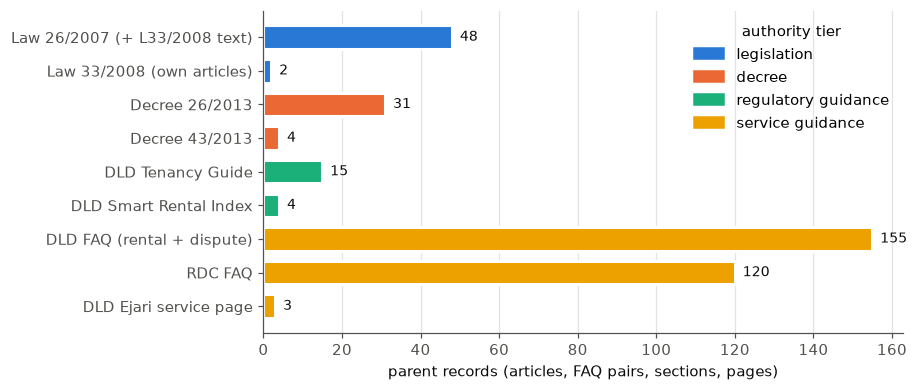

In [12]:
# Figure 1 — corpus composition (parent records per source, coloured by authority tier)
comp = P.groupby(["source", "authority_tier"]).size().reset_index(name="n")
comp["label"] = comp.source.map(NAMES)
comp["tier_rank"] = comp.authority_tier.map(TIER_ORDER.index)
comp = comp.sort_values(["tier_rank", "n"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh(comp.label, comp.n, color=comp.authority_tier.map(TIER_COLOR), height=0.7, edgecolor="white", linewidth=2)
for b, n in zip(bars, comp.n):
    ax.text(b.get_width() + 2, b.get_y() + b.get_height() / 2, str(n), va="center", fontsize=9, color=INK)
ax.set_xlabel("parent records (articles, FAQ pairs, sections, pages)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=TIER_COLOR[t]) for t in TIER_ORDER]
ax.legend(handles, [t.replace("_", " ") for t in TIER_ORDER], title="authority tier", frameon=False, loc="upper right")
fig.savefig(FIG / "fig2_1_corpus_composition.png"); plt.show()

ipykernel_29812\2463451744.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=True,


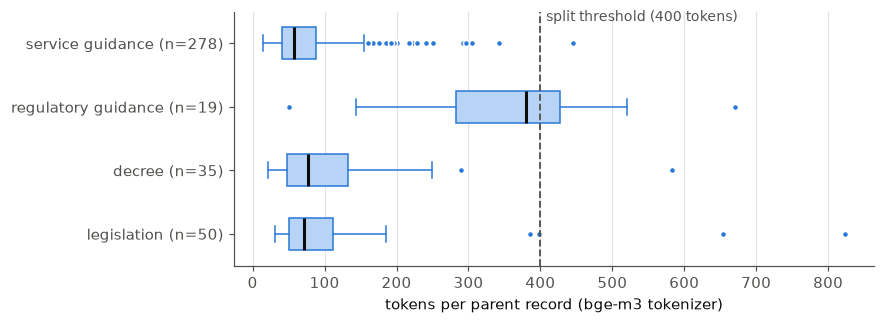

,count,mean,std,min,25%,50%,75%,max
authority_tier,,,,,,,,
legislation,50.0,117.0,148.0,31.0,50.0,72.0,112.0,823.0
decree,35.0,109.0,105.0,22.0,48.0,77.0,133.0,583.0
regulatory_guidance,19.0,352.0,148.0,50.0,283.0,380.0,427.0,670.0
service_guidance,278.0,76.0,57.0,15.0,41.0,57.0,89.0,446.0


In [13]:
# Notebook-only figure — parent length by authority tier (why only a few parents need splitting)
from tenancy_rag.preprocess.chunk import n_tokens, MAX_SINGLE
P["tokens"] = P.text.map(n_tokens)
fig, ax = plt.subplots(figsize=(7.5, 3.0))
data = [P.loc[P.authority_tier == t, "tokens"] for t in TIER_ORDER]
bp = ax.boxplot(data, vert=False, widths=0.5, patch_artist=True, showfliers=True,
                medianprops={"color": INK, "linewidth": 2}, boxprops={"facecolor": "#b7d3f6", "edgecolor": "#2a78d6"},
                whiskerprops={"color": "#2a78d6"}, capprops={"color": "#2a78d6"},
                flierprops={"marker": "o", "markersize": 4, "markerfacecolor": "#2a78d6", "markeredgecolor": "white"})
ax.set_yticks(range(1, 5), [f"{t.replace('_', ' ')} (n={len(d)})" for t, d in zip(TIER_ORDER, data)])
ax.axvline(MAX_SINGLE, color=MUTED, linestyle="--", linewidth=1.2)
ax.text(MAX_SINGLE + 8, 4.35, f"split threshold ({MAX_SINGLE} tokens)", color=MUTED, fontsize=9)
ax.set_xlabel("tokens per parent record (bge-m3 tokenizer)")
ax.grid(axis="y", visible=False)
fig.savefig(FIG / "fig2_2_parent_length_by_tier.png"); plt.show()
P.groupby("authority_tier").tokens.describe().round(0).loc[TIER_ORDER]

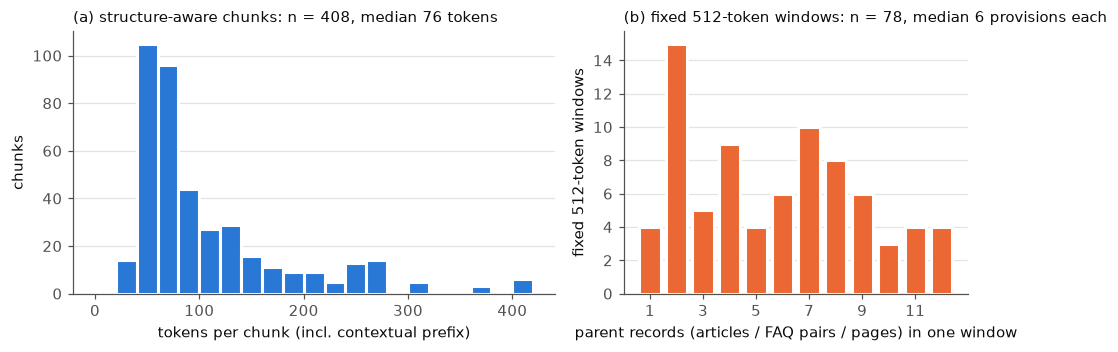

count    78.0
mean      5.8
std       3.2
min       1.0
25%       3.0
50%       6.0
75%       8.0
max      12.0
Name: provisions_spanned, dtype: float64

In [14]:
# Figure 2 — (a) structure-aware chunk length; (b) how many provisions each fixed 512-token window mixes
F["provisions_spanned"] = F.parent_ids.map(len)
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.3), gridspec_kw={"width_ratios": [1.4, 1]})
a.hist(C.n_tokens, bins=range(0, 440, 20), color="#2a78d6", edgecolor="white", linewidth=2)
a.set_xlabel("tokens per chunk (incl. contextual prefix)"); a.set_ylabel("chunks"); a.grid(axis="x", visible=False)
a.set_title(f"(a) structure-aware chunks: n = {len(C)}, median {int(C.n_tokens.median())} tokens", loc="left", fontsize=9.5, color=INK)
counts = F.provisions_spanned.value_counts().sort_index()
b.bar(counts.index, counts.values, color="#eb6834", edgecolor="white", linewidth=2, width=0.8)
b.set_xlabel("parent records (articles / FAQ pairs / pages) in one window"); b.set_ylabel("fixed 512-token windows")
b.grid(axis="x", visible=False)
b.set_title(f"(b) fixed 512-token windows: n = {len(F)}, median {int(F.provisions_spanned.median())} provisions each", loc="left", fontsize=9.5, color=INK)
b.set_xticks(range(1, int(counts.index.max()) + 1, 2))
fig.tight_layout(); fig.savefig(FIG / "fig2_3_chunking_comparison.png"); plt.show()
F.provisions_spanned.describe().round(1)

## Summary

In [15]:
n_split = int((C.groupby("parent_id").size() > 1).sum())
print(f"* {prov.parser.ne('reference_only').sum()} official sources indexed ({prov.parser.eq('reference_only').sum()} cached-only as duplicates); all {len(prov)} cached files SHA-256-verified.")
print(f"* {len(P)} parent records -> {len(C)} chunks; only {n_split} parents exceed {MAX_SINGLE} tokens, so the article *is* almost always the chunk.")
print(f"* {report['faq_duplicates_removed']} duplicate FAQ answers (shared by the DLD and RDC FAQs) folded into single records.")
print(f"* {(P.status == 'superseded').sum()} superseded records retained with status metadata (explain legal change, never cited as current).")
print(f"* {straddle/len(fixed):.0%} of fixed 512-token windows mix several provisions (median {int(F.provisions_spanned.median())}) - the case for structure-aware chunking (ablation 5).")

* 9 official sources indexed (5 cached-only as duplicates); all 14 cached files SHA-256-verified.
* 382 parent records -> 408 chunks; only 10 parents exceed 400 tokens, so the article *is* almost always the chunk.
* 49 duplicate FAQ answers (shared by the DLD and RDC FAQs) folded into single records.
* 14 superseded records retained with status metadata (explain legal change, never cited as current).
* 95% of fixed 512-token windows mix several provisions (median 6) - the case for structure-aware chunking (ablation 5).
